In [1]:
# Step 1: Import libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    encoding="latin1"
)

print("Cleaned Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Cleaned Dataset Loaded Successfully!
Dataset Shape: (180519, 51)


In [2]:
# Step 2. Delivery Status Analysis

delivery_counts = df["Delivery Status"].value_counts()

print("Delivery Status Distribution: ")
print(delivery_counts)

print("\nDelivery Status Percentage: ")
print((delivery_counts / len(df) * 100).round(2))

Delivery Status Distribution: 
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Delivery Status Percentage: 
Delivery Status
Late delivery        54.83
Advance shipping     23.04
Shipping on time     17.84
Shipping canceled     4.30
Name: count, dtype: float64


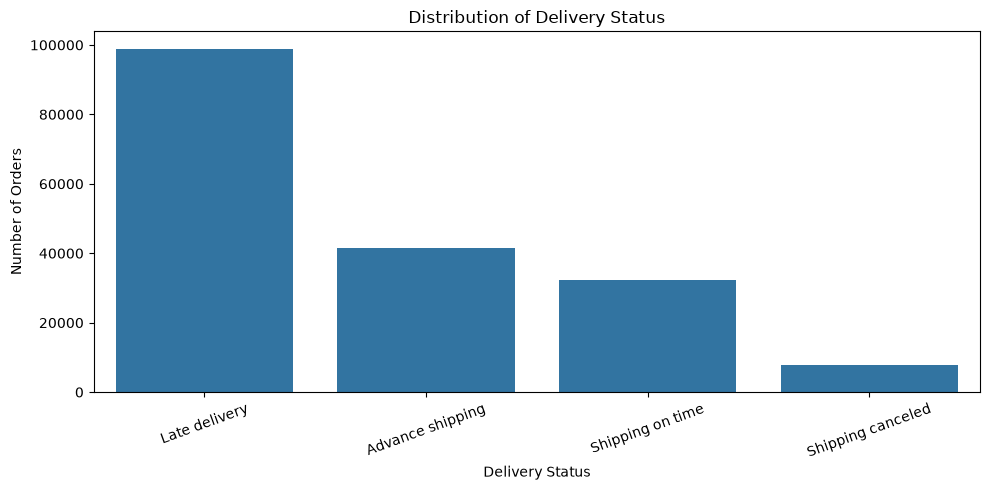

In [3]:
# Visualization

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Delivery Status",
    order=df["Delivery Status"].value_counts().index
)

plt.title("Distribution of Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [4]:
# Calculate late delivery percentage

shipping_analysis = df.groupby("Shipping Mode").agg(
    Total_Records=("Delivery Status", "count"),
    Late_Deliveries=(
        "Delivery Status",
        lambda x: (x == "Late delivery").sum()
    )
)

shipping_analysis["Late_Delivery_Percentage"] = (
    shipping_analysis["Late_Deliveries"] /
    shipping_analysis["Total_Records"] * 100
)

shipping_analysis = shipping_analysis.sort_values(
    "Late_Delivery_Percentage",
    ascending=False
)

print(shipping_analysis.round(2))

                Total_Records  Late_Deliveries  Late_Delivery_Percentage
Shipping Mode                                                           
First Class             27814            26513                     95.32
Second Class            35216            26987                     76.63
Same Day                 9737             4454                     45.74
Standard Class         107752            41023                     38.07


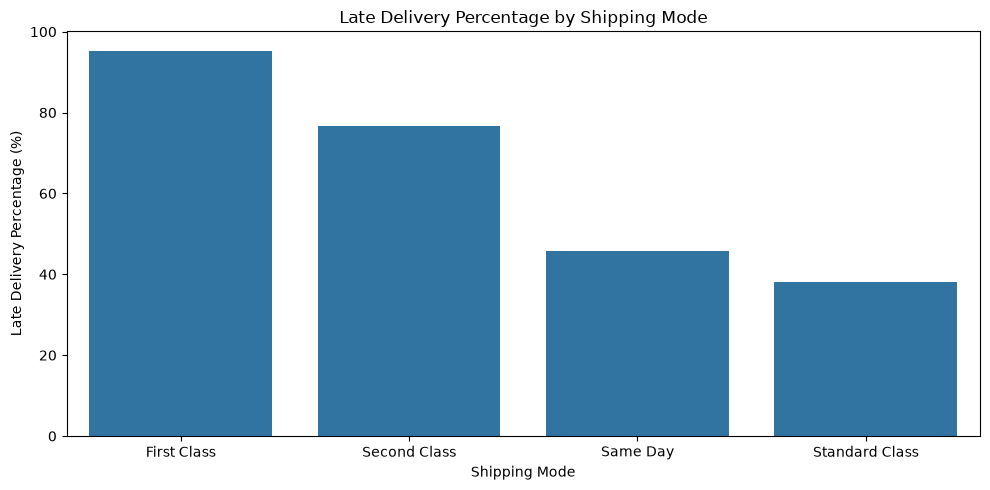

In [ ]:
# Visualization



In [6]:
# calculate delivery percentage

segment_analysis = df.groupby("Customer Segment").agg(
    Total_Orders=("Delivery Status", "count"),
    Late_Deliveries=(
        "Delivery Status",
        lambda x: (x == "Late delivery").sum()
    )
)

segment_analysis["Late_Delivery_Percentage"] = (
    segment_analysis["Late_Deliveries"] /
    segment_analysis["Total_Orders"] * 100
)

print(segment_analysis.round(2))

                  Total_Orders  Late_Deliveries  Late_Delivery_Percentage
Customer Segment                                                         
Consumer                 93504            51248                     54.81
Corporate                54789            29982                     54.72
Home Office              32226            17747                     55.07


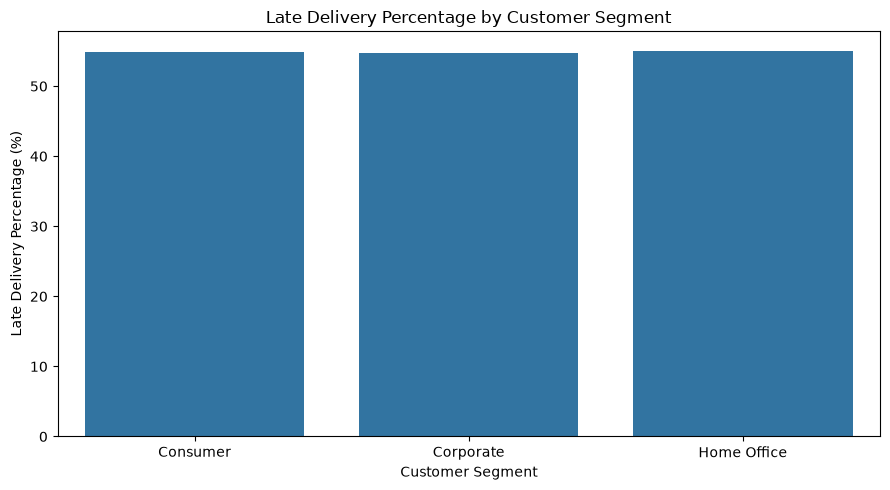

In [7]:
# visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_analysis.reset_index(),
    x="Customer Segment",
    y="Late_Delivery_Percentage"
)

plt.title("Late Delivery Percentage by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Late Delivery Percentage (%)")

plt.tight_layout()
plt.show()

In [8]:
# step 5.1 Region-wise delivery analysis

region_analysis = df.groupby("Order Region").agg(
    Total_Orders=("Delivery Status", "count"),

    Late_Deliveries=(
        "Delivery Status",
        lambda x: (x == "Late delivery").sum()
    )
)

region_analysis["Late_Delivery_Percentage"] = (
    region_analysis["Late_Deliveries"] /
    region_analysis["Total_Orders"] * 100
)

region_analysis = region_analysis.sort_values(
    "Late_Delivery_Percentage",
    ascending=False
)

print(region_analysis.round(2))

                 Total_Orders  Late_Deliveries  Late_Delivery_Percentage
Order Region                                                            
Central Africa           1677              972                     57.96
South Asia               7731             4350                     56.27
East Africa              1852             1036                     55.94
Western Europe          27109            15140                     55.85
South of  USA            4045             2256                     55.77
Eastern Europe           3920             2182                     55.66
East of USA              6915             3849                     55.66
Southeast Asia           9539             5297                     55.53
Central Asia              553              306                     55.33
West Asia                6009             3322                     55.28
US Center                5887             3252                     55.24
Central America         28341            15518     

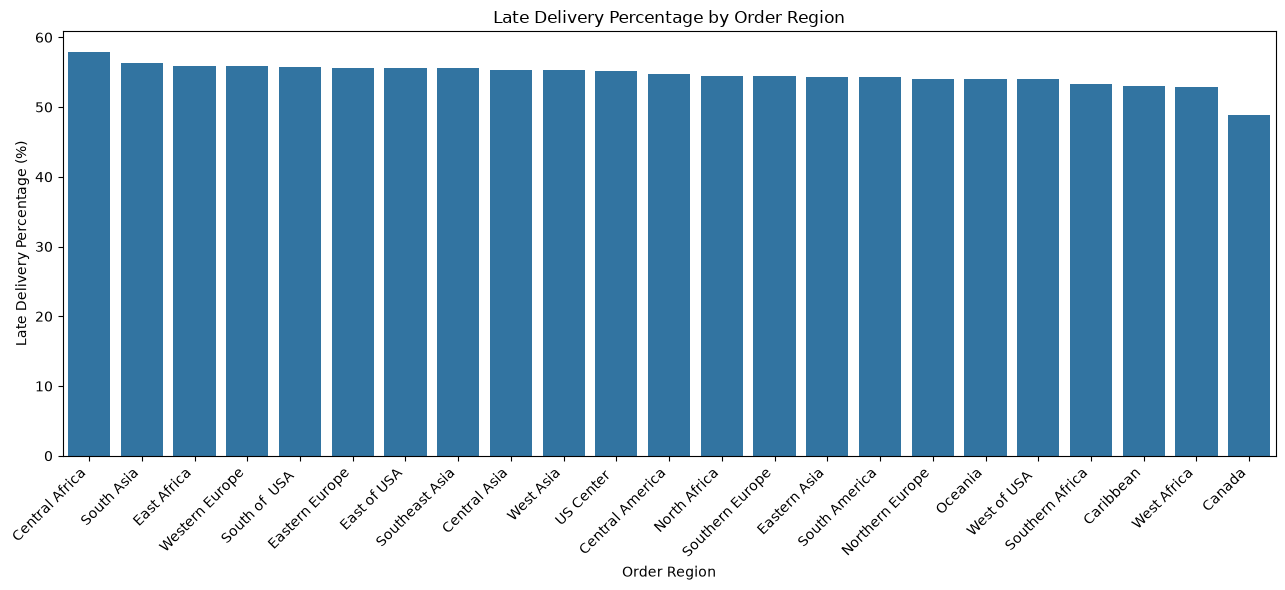

In [9]:
# visualization

plt.figure(figsize=(13, 6))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Order Region",
    y="Late_Delivery_Percentage"
)

plt.title("Late Delivery Percentage by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Late Delivery Percentage (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# step 6.1 Category-wise analysis

category_analysis = df.groupby("Category Name").agg(
    Total_Orders=("Delivery Status", "count"),

    Late_Deliveries=(
        "Delivery Status",
        lambda x: (x == "Late delivery").sum()
    )
)

category_analysis["Late_Delivery_Percentage"] = (
    category_analysis["Late_Deliveries"] /
    category_analysis["Total_Orders"] * 100
)

category_analysis = category_analysis.sort_values(
    "Late_Delivery_Percentage",
    ascending=False
)

print(category_analysis.round(2))

                      Total_Orders  Late_Deliveries  Late_Delivery_Percentage
Category Name                                                                
Golf Bags & Carts               61               42                     68.85
Lacrosse                       343              206                     60.06
Pet Supplies                   492              290                     58.94
Cameras                        592              344                     58.11
Strength Training              111               64                     57.66
As Seen on  TV!                 68               39                     57.35
Music                          434              248                     57.14
Accessories                   1780             1014                     56.97
Fitness Accessories            309              176                     56.96
Books                          405              229                     56.54
Women's Clothing               650              367             

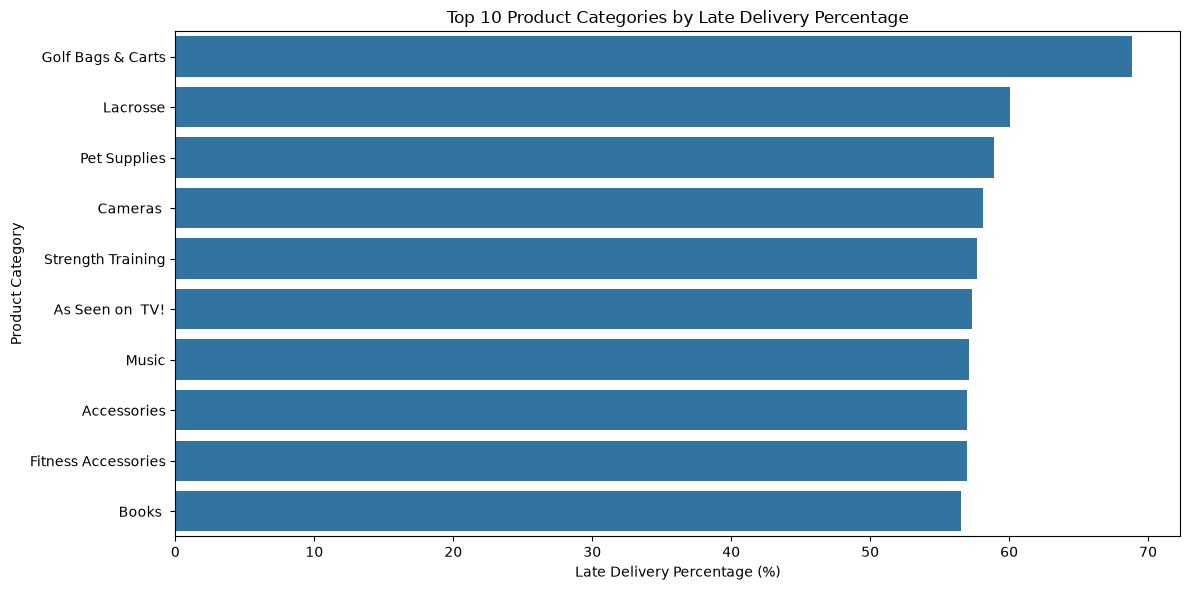

In [ ]:
# step 6.2 Top 10 categories visualize
                                                                                                    
top_categories = category_analysis.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="Late_Delivery_Percentage",
    y="Category Name"
)

plt.title("Top 10 Product Categories by Late Delivery Percentage")
plt.xlabel("Late Delivery Percentage (%)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [12]:
# step 7. Profit and Loss Analysis

profit_analysis = df["Benefit per order"].apply(
    lambda x: "Loss" if x < 0
    else "Profit" if x > 0
    else "No Profit"
)

profit_counts = profit_analysis.value_counts()

print("Profit & Loss Distribution:")
print(profit_counts)

print("\nPercentage Distribution:")
print((profit_counts / len(df) * 100).round(2))

Profit & Loss Distribution:
Benefit per order
Profit       145558
Loss          33784
No Profit      1177
Name: count, dtype: int64

Percentage Distribution:
Benefit per order
Profit       80.63
Loss         18.71
No Profit     0.65
Name: count, dtype: float64


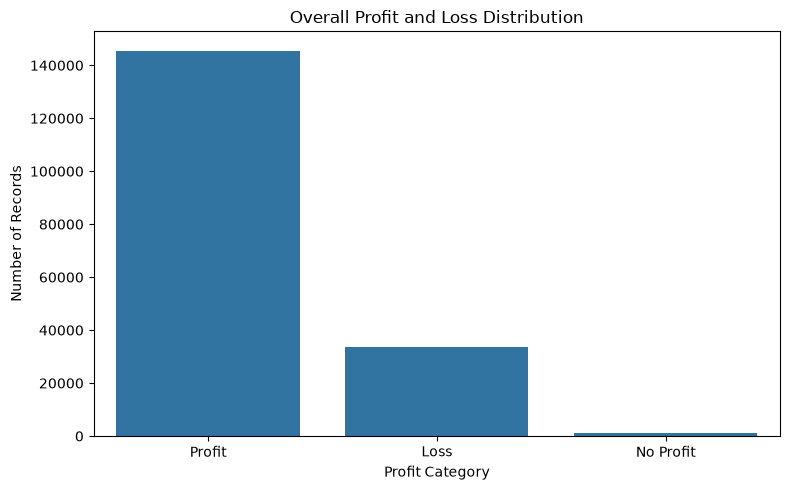

In [13]:
# visualization

plt.figure(figsize=(8, 5))

sns.countplot(
    x=profit_analysis,
    order=["Profit", "Loss", "No Profit"]
)

plt.title("Overall Profit and Loss Distribution")
plt.xlabel("Profit Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [14]:
# step 7.3 Category-wise Loss Analysis

loss_analysis = df.groupby("Category Name").agg(
    Total_Orders=("Benefit per order", "count"),

    Negative_Profit_Orders=(
        "Benefit per order",
        lambda x: (x < 0).sum()
    ),

    Average_Profit=("Benefit per order", "mean")
)

loss_analysis["Loss_Percentage"] = (
    loss_analysis["Negative_Profit_Orders"] /
    loss_analysis["Total_Orders"] * 100
)

loss_analysis = loss_analysis.sort_values(
    "Negative_Profit_Orders",
    ascending=False
)

print(loss_analysis.head(10).round(2))


                      Total_Orders  Negative_Profit_Orders  Average_Profit  \
Category Name                                                                
Cleats                       24551                    4590           20.15   
Men's Footwear               22246                    4169           14.02   
Women's Apparel              21035                    3923           16.66   
Indoor/Outdoor Games         19298                    3617           16.50   
Fishing                      17325                    3209           43.65   
Water Sports                 15540                    2924           20.92   
Camping & Hiking             13729                    2590           31.14   
Cardio Equipment             12487                    2332           30.67   
Shop By Sport                10984                    2154           11.82   
Electronics                   3156                     562           12.96   

                      Loss_Percentage  
Category Name          

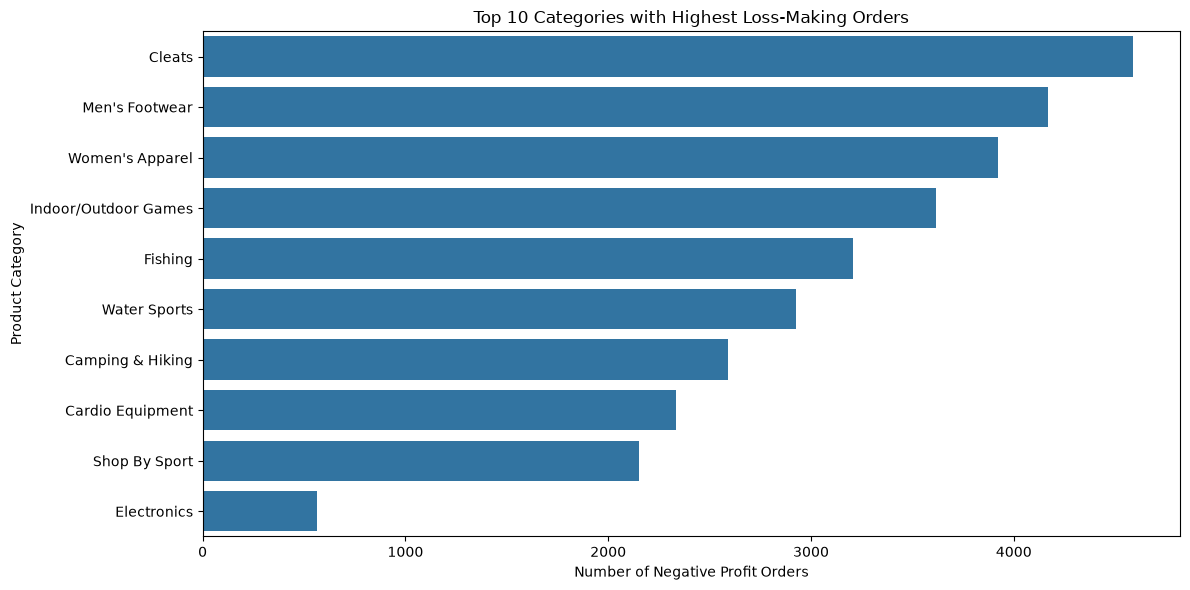

In [15]:
# step 7.4 Top 10 loss-making categories chart

top_loss_categories = (
    loss_analysis.head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_loss_categories,
    x="Negative_Profit_Orders",
    y="Category Name"
)

plt.title("Top 10 Categories with Highest Loss-Making Orders")
plt.xlabel("Number of Negative Profit Orders")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [16]:
# step 8.1 Discount vs Profit Analysis


df["Discount_Band"] = pd.cut(
    df["Order Item Discount Rate"],
    bins=[-0.001, 0.10, 0.20, 0.30, 1],
    labels=["0-10%", "10-20%", "20-30%", "Above 30%"]
)

print(df["Discount_Band"].value_counts().sort_index())

Discount_Band
0-10%        90258
10-20%       70203
20-30%       20058
Above 30%        0
Name: count, dtype: int64


In [17]:
# step 8.2 Discount-wise profit analysis

discount_analysis = df.groupby(
    "Discount_Band",
    observed=False
).agg(
    Total_Orders=("Benefit per order", "count"),

    Average_Profit=("Benefit per order", "mean"),

    Median_Profit=("Benefit per order", "median"),

    Negative_Profit_Orders=(
        "Benefit per order",
        lambda x: (x < 0).sum()
    )
)

discount_analysis["Loss_Percentage"] = (
    discount_analysis["Negative_Profit_Orders"] /
    discount_analysis["Total_Orders"] * 100
)

print(discount_analysis.round(2))

               Total_Orders  Average_Profit  Median_Profit  \
Discount_Band                                                
0-10%                 90258           23.75          33.80   
10-20%                70203           20.71          29.92   
20-30%                20058           18.41          27.04   
Above 30%                 0             NaN            NaN   

               Negative_Profit_Orders  Loss_Percentage  
Discount_Band                                           
0-10%                           16734            18.54  
10-20%                          13233            18.85  
20-30%                           3817            19.03  
Above 30%                           0              NaN  


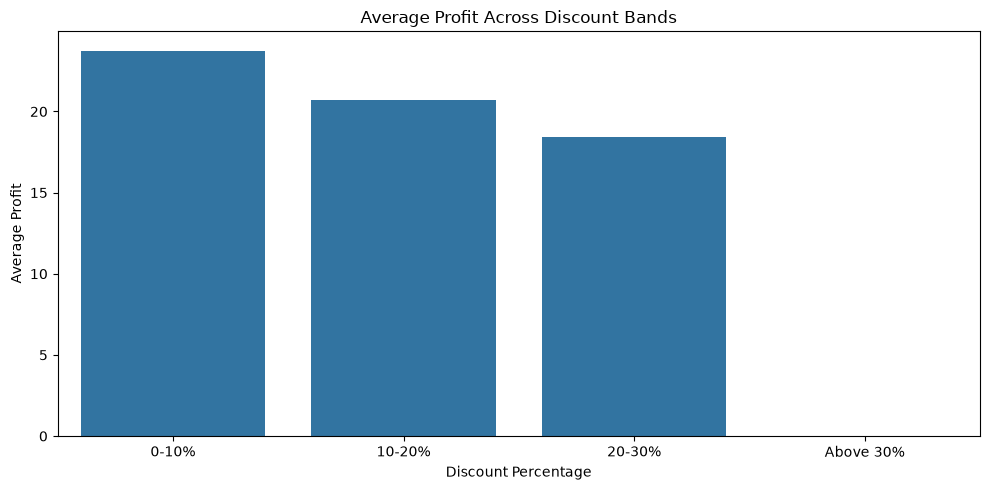

In [18]:
# visualization

plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis.reset_index(),
    x="Discount_Band",
    y="Average_Profit"
)

plt.title("Average Profit Across Discount Bands")
plt.xlabel("Discount Percentage")
plt.ylabel("Average Profit")

plt.tight_layout()
plt.show()


In [21]:
# step 9.1 select numerical columns

numerical_df = df.select_dtypes(include=["number"])

print("Total Numerical Columns: ", len(numerical_df.columns))

print("\nNumerical Columns: ")
print(numerical_df.columns.tolist())

Total Numerical Columns:  27

Numerical Columns: 
['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Card Id', 'Product Category Id', 'Product Price', 'Product Status']


In [22]:
# step 9.2 Correlation matrix calculate 

correlation_matrix = numerical_df.corr()

print(correlation_matrix.round(2))

                               Days for shipping (real)  \
Days for shipping (real)                           1.00   
Days for shipment (scheduled)                      0.52   
Benefit per order                                 -0.01   
Sales per customer                                 0.00   
Late_delivery_risk                                 0.40   
Category Id                                       -0.00   
Customer Id                                        0.00   
Customer Zipcode                                   0.00   
Department Id                                     -0.00   
Latitude                                          -0.00   
Longitude                                          0.00   
Order Customer Id                                  0.00   
Order Id                                          -0.00   
Order Item Cardprod Id                            -0.00   
Order Item Discount                                0.00   
Order Item Discount Rate                           0.00 

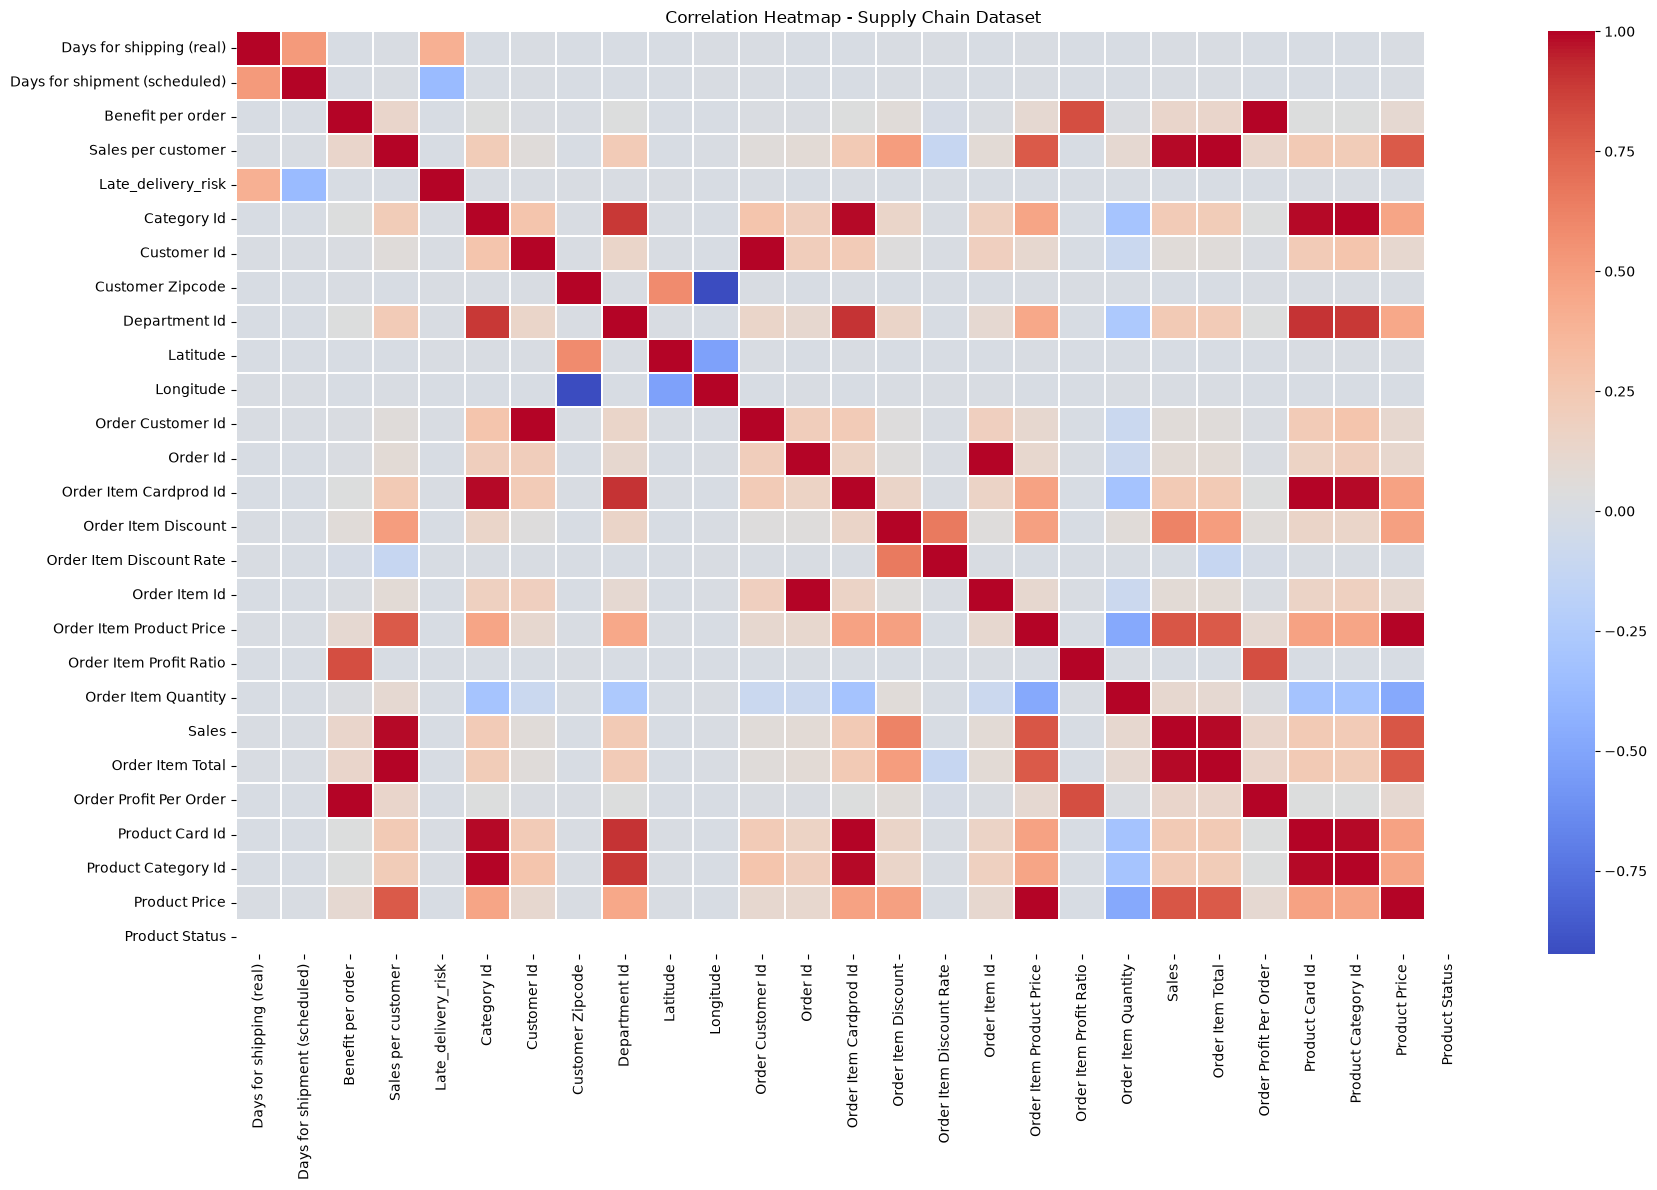

In [24]:
# step 9.3 correlation Heatmap

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap - Supply Chain Dataset")
plt.tight_layout()
plt.show()

In [25]:
# step 9.4 Strong correlations identify

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strong_correlations = (
    upper_triangle.stack()
    .reset_index()
)

strong_correlations.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

strong_correlations["Abs_Correlation"] = (
    strong_correlations["Correlation"].abs()
)

strong_correlations = strong_correlations.sort_values(
    "Abs_Correlation",
    ascending=False
)

print(strong_correlations.head(15).round(3))


                    Feature_1               Feature_2  Correlation  \
484  Order Item Product Price           Product Price        1.000   
374    Order Item Cardprod Id         Product Card Id        1.000   
173               Customer Id       Order Customer Id        1.000   
102        Sales per customer        Order Item Total        1.000   
76          Benefit per order  Order Profit Per Order        1.000   
159               Category Id     Product Category Id        1.000   
340                  Order Id           Order Item Id        1.000   
375    Order Item Cardprod Id     Product Category Id        0.991   
148               Category Id  Order Item Cardprod Id        0.991   
645           Product Card Id     Product Category Id        0.991   
158               Category Id         Product Card Id        0.991   
101        Sales per customer                   Sales        0.990   
561                     Sales        Order Item Total        0.990   
199          Custome